# EDA: Bank Marketing (UCI id=222) — Левин

**Кейс.** Португальский банк обзванивал клиентов (2008–2010) и предлагал срочный депозит. Цель `y` — согласился ли клиент (`yes`/`no`).
**Зачем EDA.** Понять данные до построения предиктора: качество, смысл признаков, утечки, закономерности, идеи для фичей.

**План:**
1. Загрузка и оптимизация памяти
2. Качество данных: пропуски, дубликаты, выбросы, «скрытые» структуры
3. Целевая переменная
4. Числовые и категориальные признаки vs. таргет
5. Проверка гипотез (со статистическими тестами)
6. Утечка `duration` — количественно, через baseline-модель
7. Идеи для фичей и итоговые выводы

## 0. Импорты и настройки

In [1]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.feature_selection import mutual_info_classif

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.figsize'] = (9, 4.5)
pd.set_option('display.max_columns', 50, 'display.width', 140)
SEED = 42

## 1. Загрузка и оптимизация памяти
**Зачем:** датасет небольшой, но привычка важна — на больших выборках `object` и `int64` раздувают память. Строки → `category`, числа → минимальный целочисленный тип.

In [2]:
bm = fetch_ucirepo(id=222)
df_raw = pd.concat([bm.data.features, bm.data.targets], axis=1)
print(df_raw.shape)
display(bm.variables[['name','role','type','description','missing_values']])

(45211, 17)


,name,role,type,description,missing_values
0,age,Feature,Integer,NaN,no
1,job,Feature,Categorical,"type of job (categorical: 'admin.','blue-colla...",no
2,marital,Feature,Categorical,"marital status (categorical: 'divorced','marri...",no
3,education,Feature,Categorical,"(categorical: 'basic.4y','basic.6y','basic.9y'...",no
4,default,Feature,Binary,has credit in default?,no
5,balance,Feature,Integer,average yearly balance,no
6,housing,Feature,Binary,has housing loan?,no
7,loan,Feature,Binary,has personal loan?,no
8,contact,Feature,Categorical,contact communication type (categorical: 'cell...,yes
9,day_of_week,Feature,Date,last contact day of the week,no


In [3]:
def optimize(df):
    df = df.copy()
    for c in df.columns:
        s = df[c]
        if pd.api.types.is_integer_dtype(s):
            df[c] = pd.to_numeric(s, downcast='integer')
        elif pd.api.types.is_float_dtype(s):
            df[c] = pd.to_numeric(s, downcast='float')
        else:
            df[c] = s.astype('category')
    return df

before = df_raw.memory_usage(deep=True).sum() / 1024**2
df = optimize(df_raw)
after = df.memory_usage(deep=True).sum() / 1024**2
print(f'Память (deep): {before:.2f} МБ -> {after:.2f} МБ  (−{100*(1-after/before):.0f}%)')  # deep=True считает реальный размер строк
df.dtypes.to_frame('dtype').T

Память (deep): 24.56 МБ -> 0.99 МБ  (−96%)


,age,job,marital,education,default,balance,housing,loan,contact,day_of_week,month,duration,campaign,pdays,previous,poutcome,y
dtype,int8,category,category,category,category,int32,category,category,category,int8,category,int16,int8,int16,int16,category,category


## 2. Качество данных
### 2.1 Пропуски и дубликаты
**Зачем:** в UCI-описании пропусков «нет», но в данных `NaN` есть. Важно понять, это *случайная потеря* или *осмысленное отсутствие*.

In [4]:
print('Дубликатов строк:', df.duplicated().sum())
miss = df.isna().agg(['sum','mean']).T.rename(columns={'sum':'n','mean':'share'})
miss[miss.n>0].sort_values('share', ascending=False).style.format({'share':'{:.1%}'})

Дубликатов строк: 0


,n,share
poutcome,36959.000000,81.7%
contact,13020.000000,28.8%
education,1857.000000,4.1%
job,288.000000,0.6%


**Гипотеза H1: пропуски в `poutcome` — не потеря, а «клиента раньше не обзванивали».**
Проверяем связь `poutcome=NaN` ↔ `pdays=-1` ↔ `previous=0`.

In [5]:
print(pd.crosstab(df.pdays == -1, df.previous == 0, rownames=['pdays==-1'], colnames=['previous==0']))
print()
print(pd.crosstab(df.poutcome.isna(), df.pdays == -1, rownames=['poutcome NaN'], colnames=['pdays==-1']))

previous==0  False  True 
pdays==-1                
False         8257      0
True             0  36954

pdays==-1     False  True 
poutcome NaN              
False          8252      0
True              5  36954


**Вывод H1: подтверждена.** `pdays=-1` ⇔ `previous=0` (полное совпадение). `poutcome=NaN` почти совпадает с ними (5 строк — исключения: предыдущий контакт был, но исход не записан).
Значит `poutcome=NaN` — это категория **«нет предыдущей кампании»** (82% клиентов), а не пропуск. Для модели: заполнять как отдельную категорию `no_prev`, а не импьютить модой. Заодно `pdays=-1` — это **маркер**, а не число: подавать его в линейную модель как есть нельзя (будет «близко к 0 дней»).

**Гипотеза H2: пропуски `contact` — не случайны, а привязаны ко времени.**

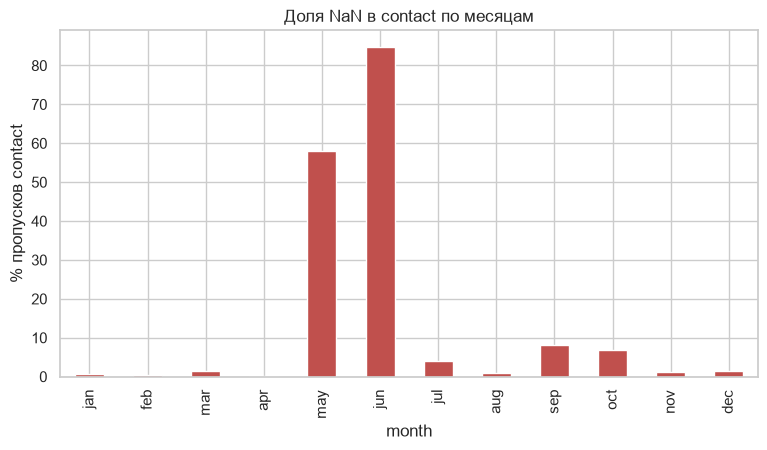

contact
False    0.147836
True     0.040707
Name: conv. rate, dtype: float64


In [6]:
tab = pd.crosstab(df.month, df.contact.isna(), normalize='index')[True].reindex(
    ['jan','feb','mar','apr','may','jun','jul','aug','sep','oct','nov','dec'])
ax = (tab*100).plot.bar(color='#c0504d'); ax.set_ylabel('% пропусков contact'); ax.set_title('Доля NaN в contact по месяцам')
plt.show()
print(df.groupby(df.contact.isna(), observed=True).y.apply(lambda s: (s=='yes').mean()).rename('conv. rate'))

**Вывод H2: подтверждена.** `contact` пропущен почти исключительно в **мае и июне** (в этих месяцах в данных, вероятно, не записывали канал связи), а конверсия у таких строк всего ~4% против ~15% у остальных. То есть `contact=NaN` — это одновременно **артефакт сбора данных** и сильный сигнал. Нужен явный флаг `contact_unknown`; но осторожно — он частично дублирует месяц.

Остальные пропуски (`education` 4%, `job` 0.6%) — небольшие; тоже оставляем как категорию `unknown`: у `education=NaN` конверсия отличается от остальных (см. раздел 4), так что сам факт пропуска информативен.

### 2.2 «Скрытая» структура времени
**Зачем:** в данных нет года, а `day_of_week` по описанию — «день недели». Проверим, что это на самом деле. Если данные упорядочены хронологически, то это (а) позволяет восстановить дату, (б) **определяет, как делить на train/test** — случайный split даст оптимистичную оценку.

In [7]:
print('day_of_week: min/max =', df.day_of_week.min(), df.day_of_week.max(), '| уникальных:', df.day_of_week.nunique())
months = ['jan','feb','mar','apr','may','jun','jul','aug','sep','oct','nov','dec']
mnum = df.month.astype(str).map({m:i+1 for i,m in enumerate(months)})
# новый год наступает, когда номер месяца в потоке строк «сбрасывается» назад
year = 2008 + (mnum.diff().fillna(0) < 0).cumsum()
print(year.value_counts().sort_index())

day_of_week: min/max = 1 31 | уникальных: 31


month
2008    27729
2009    14862
2010     2620
Name: count, dtype: int64


**Вывод:** `day_of_week` принимает значения 1–31 → это **день месяца**, а не день недели (название в UCI вводит в заблуждение). Строки идут в хронологическом порядке, и «сброс» номера месяца даёт ровно 3 года: 2008, 2009, 2010 — что соответствует описанию датасета (май 2008 – ноябрь 2010). Восстановим дату и проверим конверсию по времени.

Невалидных дат (напр. 31 июня): 0


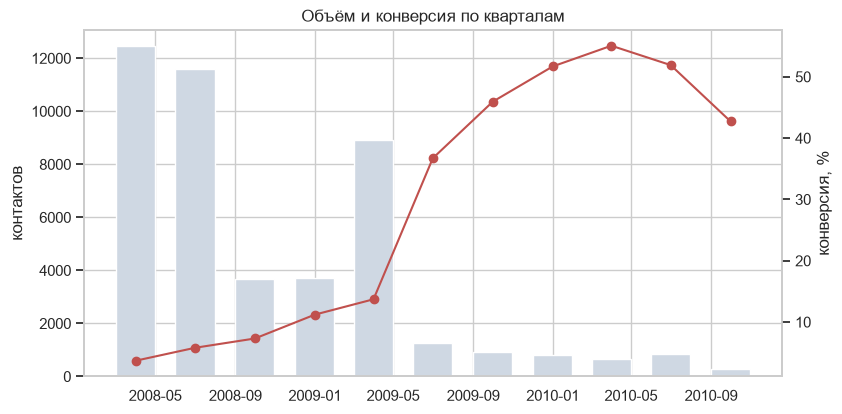

In [8]:
df['year'] = year.astype('int16'); df['month_num'] = mnum.astype('int8'); df['day'] = df.day_of_week.astype('int8')
df['date'] = pd.to_datetime(dict(year=df.year, month=df.month_num, day=df.day), errors='coerce')
print('Невалидных дат (напр. 31 июня):', df.date.isna().sum())
df['target'] = (df.y == 'yes').astype('int8')
m = df.dropna(subset=['date']).set_index('date').target.resample('QS').agg(['mean','size'])
fig, ax = plt.subplots(); ax.bar(m.index, m['size'], width=60, color='#cfd8e3', label='кол-во контактов')
ax2 = ax.twinx(); ax2.plot(m.index, m['mean']*100, 'o-', color='#c0504d'); ax2.set_ylabel('конверсия, %'); ax.set_ylabel('контактов')
ax.set_title('Объём и конверсия по кварталам'); ax2.grid(False); plt.show()

**Вывод:** конверсия **радикально нестабильна во времени**: по годам ≈ **5% (2008, 27.7 тыс. контактов) → 17% (2009, 14.9 тыс.) → 52% (2010, 2.6 тыс.)**. В 2008 был массовый обзвон с низкой отдачей, дальше банк звонил всё меньшему и более целевому кругу. Это самая большая «скрытая» закономерность в данных и главный риск для модели: **валидироваться надо по времени** (train — раньше, test — позже), иначе оценка качества будет завышена, а признаки вроде месяца будут «подсматривать» год (см. H4 и раздел 6).

### 2.3 Выбросы и странные значения
**Зачем:** решаем, что делать с хвостами (клиппинг, лог-преобразование, робастные модели).

In [9]:
num = ['age','balance','duration','campaign','pdays','previous']
display(df[num].describe(percentiles=[.01,.5,.99]).T.round(1))
print('Клиентов с отрицательным balance: {:.1%}'.format((df.balance<0).mean()))
print('previous > 20:', (df.previous>20).sum(), '| campaign > 20:', (df.campaign>20).sum())

,count,mean,std,min,1%,50%,99%,max
age,45211.0,40.9,10.6,18.0,23.0,39.0,71.0,95.0
balance,45211.0,1362.3,3044.8,-8019.0,-627.0,448.0,13164.9,102127.0
duration,45211.0,258.2,257.5,0.0,11.0,180.0,1269.0,4918.0
campaign,45211.0,2.8,3.1,1.0,1.0,2.0,16.0,63.0
pdays,45211.0,40.2,100.1,-1.0,-1.0,-1.0,370.0,871.0
previous,45211.0,0.6,2.3,0.0,0.0,0.0,8.9,275.0


Клиентов с отрицательным balance: 8.3%
previous > 20: 55 | campaign > 20: 244


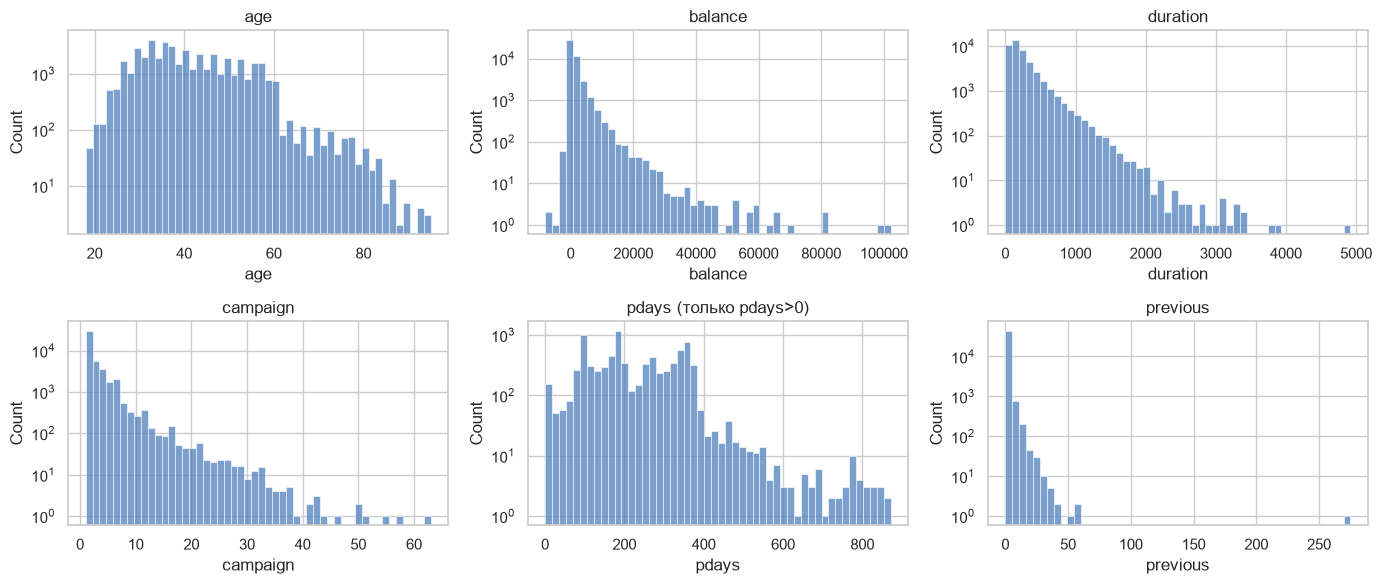

In [10]:
fig, axs = plt.subplots(2, 3, figsize=(14, 6))
for ax, c in zip(axs.ravel(), num):
    sns.histplot(df[c] if c!='pdays' else df.loc[df.pdays>0,'pdays'], bins=50, ax=ax, color='#4f81bd'); ax.set_title(c + (' (только pdays>0)' if c=='pdays' else ''))
    ax.set_yscale('log')
plt.tight_layout(); plt.show()

**Вывод:** все числовые признаки сильно скошены вправо с длинными хвостами (log-шкала): `balance` до 102 127 (и 8% отрицательных), `campaign` до 63, `previous` до 275 (выброс-одиночка), `duration` до 4918 сек. Это реальные, а не ошибочные значения — удалять не нужно, но для линейных моделей: `log1p`/клиппинг по 99-му перцентилю; для деревьев — можно оставить как есть.

## 3. Целевая переменная
**Зачем:** дисбаланс определяет метрики (accuracy бесполезна) и способ валидации.

In [11]:
vc = df.y.value_counts(); print(vc.to_string()); print(f'Доля yes: {df.target.mean():.2%}')
print(f'Тривиальный классификатор «всем no» даёт accuracy = {1-df.target.mean():.2%}')

y
no     39922
yes     5289
Доля yes: 11.70%
Тривиальный классификатор «всем no» даёт accuracy = 88.30%


**Вывод:** классы несбалансированы — `yes` ≈ **11.7%** (1 к ~7.5). Accuracy ≈ 88% достигается, если просто всем говорить «нет», поэтому оцениваем **ROC-AUC / PR-AUC / F1 / lift**, используем стратифицированные фолды (или временной split) и при необходимости `class_weight` / подбор порога. Бизнес-смысл: банку важен не «угадать всех», а ранжировать клиентов так, чтобы звонить в первую очередь тем, у кого вероятность выше (lift@k).

## 4. Признаки против таргета
**Зачем:** увидеть, какие признаки дают сигнал и в какой форме (монотонно, U-образно, порогово) — это определяет, нужны ли бинирование и взаимодействия.

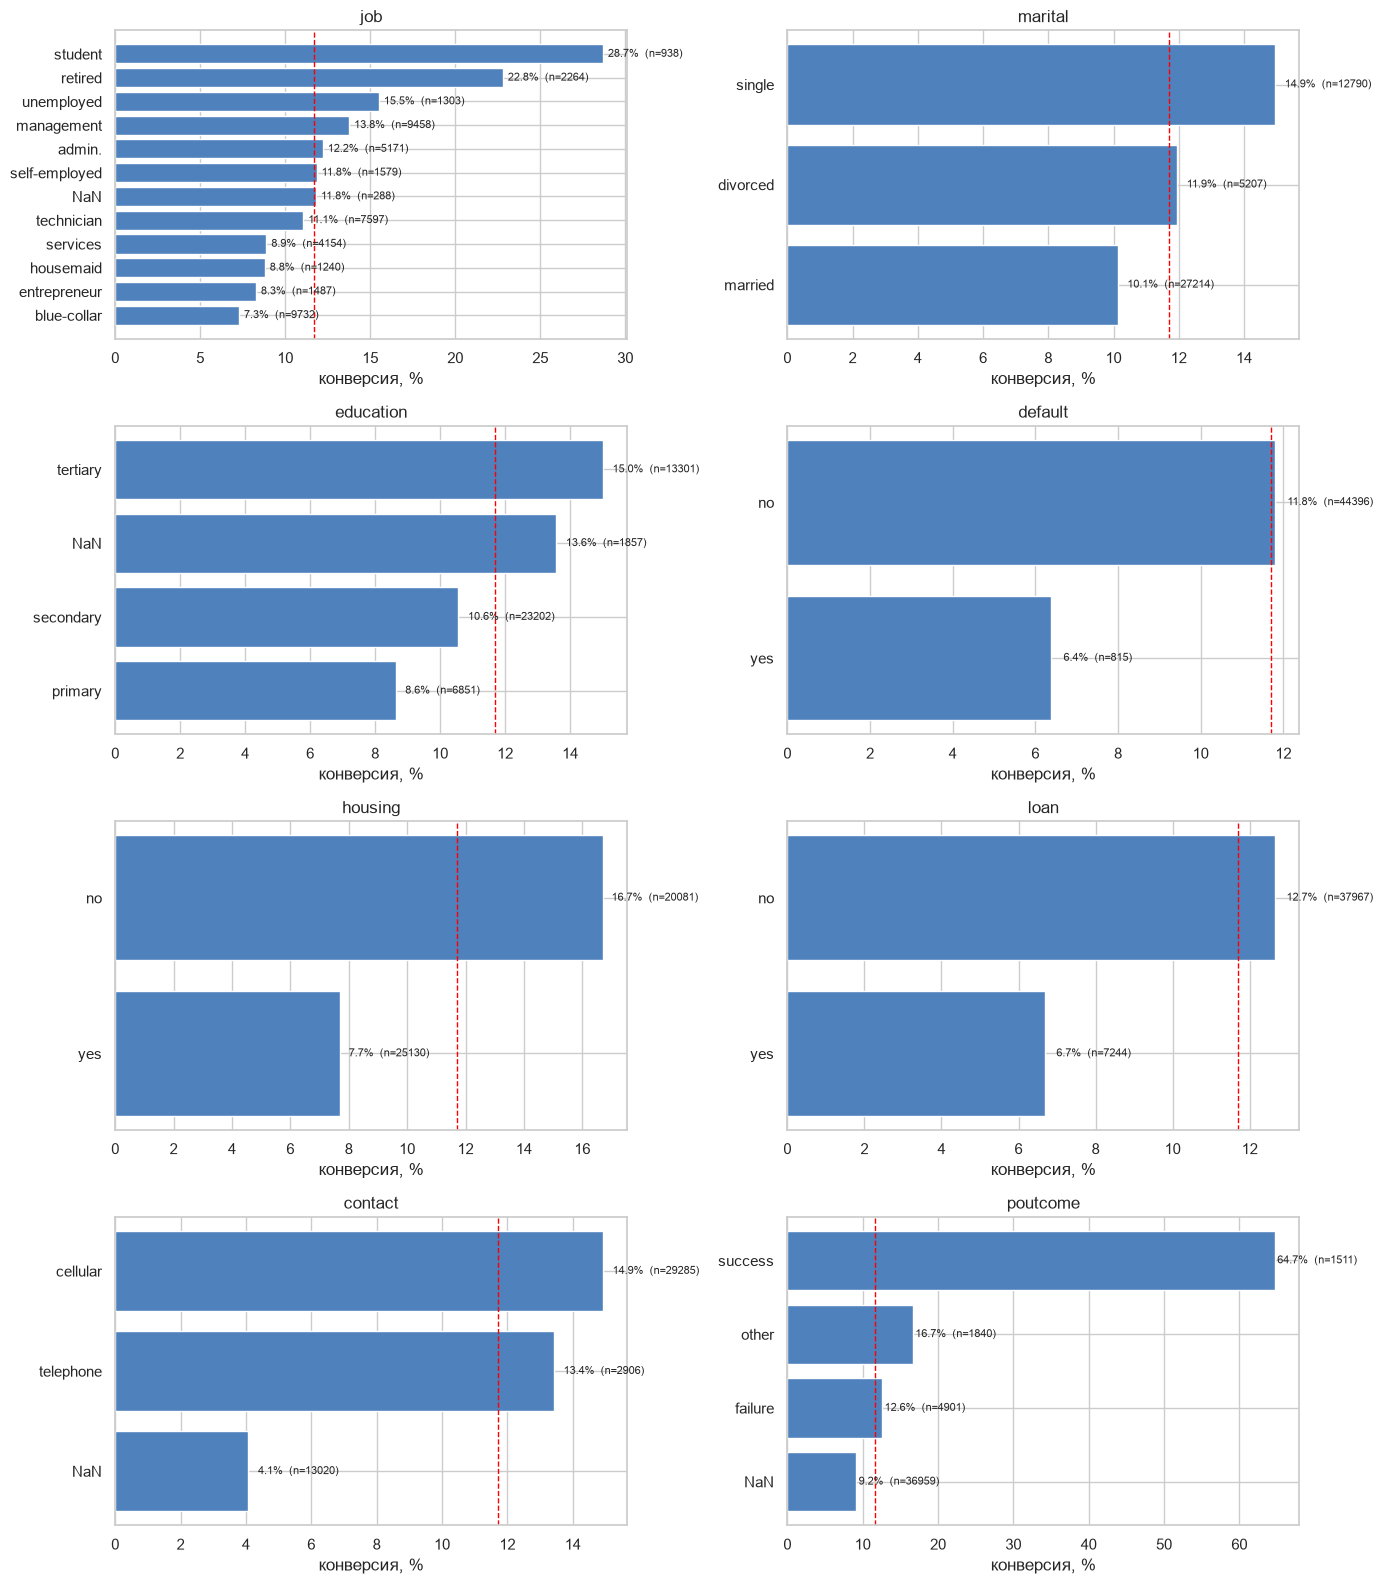

In [12]:
def rate_plot(col, order=None, ax=None, title=None, min_n=0):
    g = df.groupby(df[col].astype('object').fillna('NaN'), observed=True).target.agg(['mean','size'])
    g = g[g['size']>=min_n]
    g = g.loc[order] if order else g.sort_values('mean')
    ax = ax or plt.gca()
    ax.barh(g.index.astype(str), g['mean']*100, color='#4f81bd')
    for i,(r,n) in enumerate(zip(g['mean'], g['size'])): ax.text(r*100+.3, i, f'{r:.1%}  (n={n})', va='center', fontsize=8)
    ax.axvline(df.target.mean()*100, color='red', ls='--', lw=1); ax.set_title(title or col); ax.set_xlabel('конверсия, %')

cats = ['job','marital','education','default','housing','loan','contact','poutcome']
fig, axs = plt.subplots(4, 2, figsize=(14, 16))
for ax, c in zip(axs.ravel(), cats): rate_plot(c, ax=ax)
plt.tight_layout(); plt.show()

**Что видно (красная линия — средняя конверсия 11.7%):**
- **job:** `student` (28.7%) и `retired` (22.8%) конвертируются в 2–3 раза лучше среднего; `blue-collar` (7.3%), `entrepreneur`, `housemaid`, `services` — хуже.
- **education:** монотонно растёт `primary` → `secondary` → `tertiary` (8.6% → 10.6% → 15.0%).
- **housing / loan:** клиенты с ипотекой (7.7% vs 16.7%) и потребкредитом (6.7% vs 12.7%) соглашаются значительно реже — логично: деньги уже «заняты».
- **default=yes:** 6.4% против 11.8%, но таких всего 815 (1.8%) — признак слабый из-за редкости.
- **marital:** `single` (14.9%) > `divorced` (11.9%) > `married` (10.1%); частично это эффект возраста.
- **poutcome:** `success` — **64.7%** (!), `failure` 12.6%, `other` 16.7%, нет контакта (NaN) 9.2%. Результат прошлой кампании — самый сильный «чистый» категориальный предиктор.
- **contact:** `cellular` 14.9%, `telephone` 13.4%, `NaN` 4.1% (см. H2).

### 4.1 Числовые признаки: форма зависимости

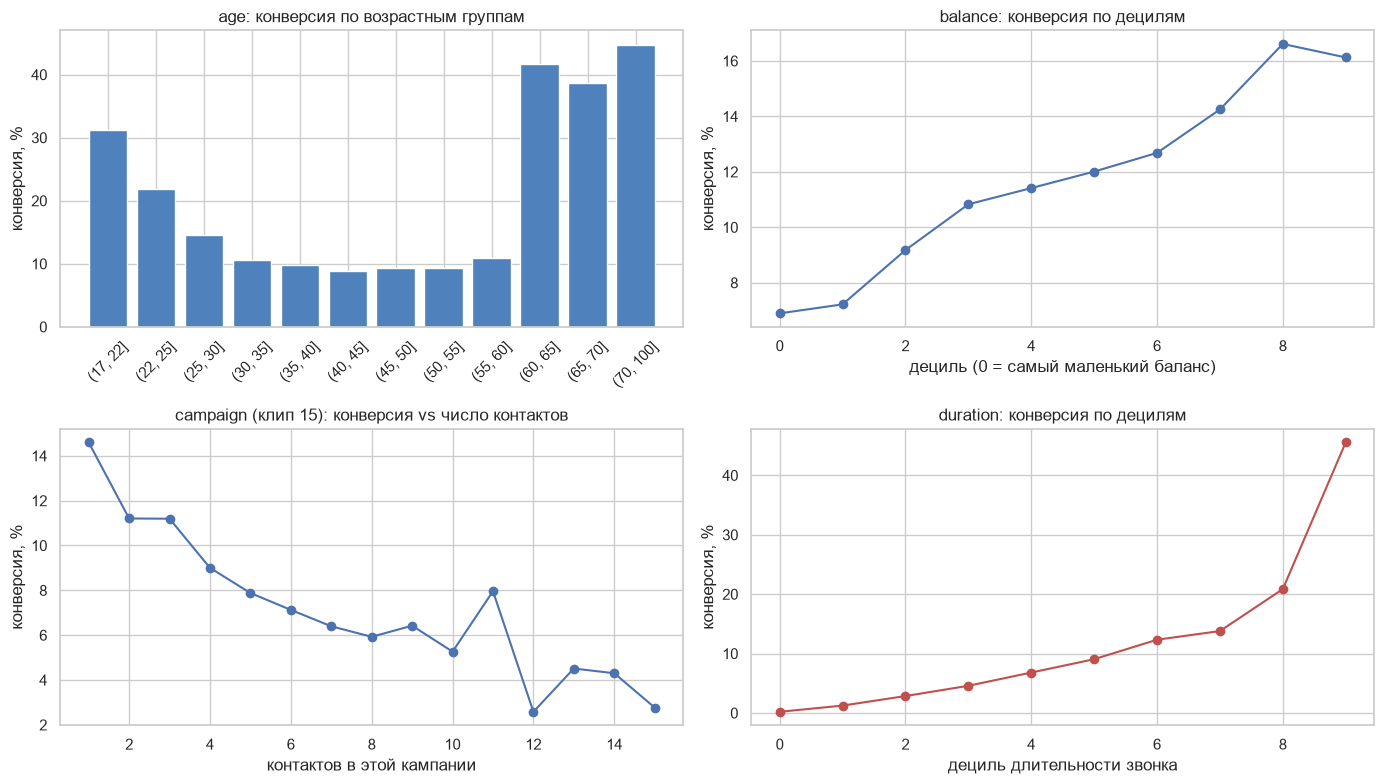

In [13]:
fig, axs = plt.subplots(2, 2, figsize=(14, 8))
# age
g = df.groupby(pd.cut(df.age,[17,22,25,30,35,40,45,50,55,60,65,70,100]), observed=True).target.agg(['mean','size'])
axs[0,0].bar(g.index.astype(str), g['mean']*100, color='#4f81bd'); axs[0,0].set_title('age: конверсия по возрастным группам'); axs[0,0].tick_params(axis='x', rotation=45)
# balance deciles
g = df.groupby(pd.qcut(df.balance,10,duplicates='drop'), observed=True).target.mean()
axs[0,1].plot(range(len(g)), g.values*100, 'o-'); axs[0,1].set_title('balance: конверсия по децилям'); axs[0,1].set_xlabel('дециль (0 = самый маленький баланс)')
# campaign
g = df.groupby(df.campaign.clip(upper=15)).target.agg(['mean','size'])
axs[1,0].plot(g.index, g['mean']*100, 'o-'); axs[1,0].set_title('campaign (клип 15): конверсия vs число контактов'); axs[1,0].set_xlabel('контактов в этой кампании')
# duration deciles
g = df.groupby(pd.qcut(df.duration,10), observed=True).target.mean()
axs[1,1].plot(range(len(g)), g.values*100, 'o-', color='#c0504d'); axs[1,1].set_title('duration: конверсия по децилям'); axs[1,1].set_xlabel('дециль длительности звонка')
for a in axs.ravel(): a.set_ylabel('конверсия, %')
plt.tight_layout(); plt.show()

**Что видно:**
- **age — U-образная зависимость:** до 25 лет ≈ 24%, 60+ ≈ 42%, а в середине (30–60) всего ≈ 9–10%. Линейно возраст в модель подавать нельзя — нужны бины/сплайны или деревья. Это же объясняет, почему `student`/`retired` — лидеры по job.
- **balance — монотонный рост:** от ≈ 7% (баланс ≤ 0) до ≈ 16% (верхние децили), дальше выходит на плато. Хороши `log`-преобразование и флаг `balance<=0`.
- **campaign — убывающая:** 14.6% при 1 контакте → ~4% при 10+. «Назойливость» не помогает; после ~3–5 звонков отдача падает.
- **duration — резко растёт** (0.2% → 45.5%), но это **утечка**, см. раздел 6.

## 5. Проверка гипотез со статистикой
Ниже — формальная проверка основных гипотез, которые влияют на построение предиктора. Для категориальных — χ² и **V Крамера** (сила связи, 0..1), для числовых — тест Манна-Уитни (не требует нормальности) и AUC одного признака.

In [14]:
def cramers_v(a, b):
    ct = pd.crosstab(a, b); chi2 = stats.chi2_contingency(ct, correction=False)[0]
    n = ct.values.sum(); return np.sqrt(chi2 / (n * (min(ct.shape) - 1))), stats.chi2_contingency(ct)[1]

rows = []
for c in ['job','marital','education','default','housing','loan','contact','month','poutcome']:
    v, p = cramers_v(df[c].astype('object').fillna('NaN'), df.target); rows.append((c, 'cat', v, p))
for c in ['age','balance','duration','campaign','pdays','previous','day']:
    a, b = df.loc[df.target==1, c], df.loc[df.target==0, c]
    u, p = stats.mannwhitneyu(a, b); auc = u/(len(a)*len(b)); rows.append((c, 'num', abs(auc-.5)*2, p))
res = pd.DataFrame(rows, columns=['feature','type','effect_size','p_value']).sort_values('effect_size', ascending=False)
res['significant(p<0.001)'] = res.p_value < 1e-3
res.style.format({'effect_size':'{:.3f}','p_value':'{:.1e}'}).background_gradient(subset=['effect_size'], cmap='Blues')

,feature,type,effect_size,p_value,significant(p<0.001)
11,duration,num,0.615,0.0e+00,True
8,poutcome,cat,0.312,0.0e+00,True
7,month,cat,0.260,0.0e+00,True
14,previous,num,0.205,3.5e-283,True
13,pdays,num,0.186,2.5e-235,True
10,balance,num,0.180,6.6e-101,True
6,contact,cat,0.151,1.3e-225,True
12,campaign,num,0.145,1.9e-71,True
4,housing,cat,0.139,2.9e-192,True
0,job,cat,0.136,3.3e-172,True


*effect_size:* для категориальных — V Крамера; для числовых — `2·|AUC−0.5|` (т.е. коэффициент Сомерса, 0 = нет связи, 1 = идеальное разделение).
**Важно:** при n = 45 тыс. почти любой p-value будет ≈ 0, поэтому ориентируемся на **размер эффекта**, а не на «значимо/не значимо».

### H3. `duration` — самый сильный признак, но он недоступен на момент решения (утечка)

In [15]:
print(df.groupby('target').duration.describe().round(0))
print('\nМедиана длительности, сек: yes =', df.loc[df.target==1,'duration'].median(), '| no =', df.loc[df.target==0,'duration'].median())

          count   mean    std  min    25%    50%    75%     max
target                                                         
0       39922.0  221.0  207.0  0.0   95.0  164.0  279.0  4918.0
1        5289.0  537.0  393.0  8.0  244.0  426.0  725.0  3881.0

Медиана длительности, сек: yes = 426.0 | no = 164.0


Звонок идёт дольше, когда клиент заинтересован, т.е. `duration` — **следствие**, а не причина. Длительность известна только *после* звонка, а предиктор нужен, чтобы решить *кого обзванивать*. Это классическая утечка (UCI прямо пишет: «для реалистичной модели признак стоит выбросить»). Количественно оценим эффект в разделе 6.

### H4. Сезонность: конверсия сильно зависит от месяца, причём не из-за объёма

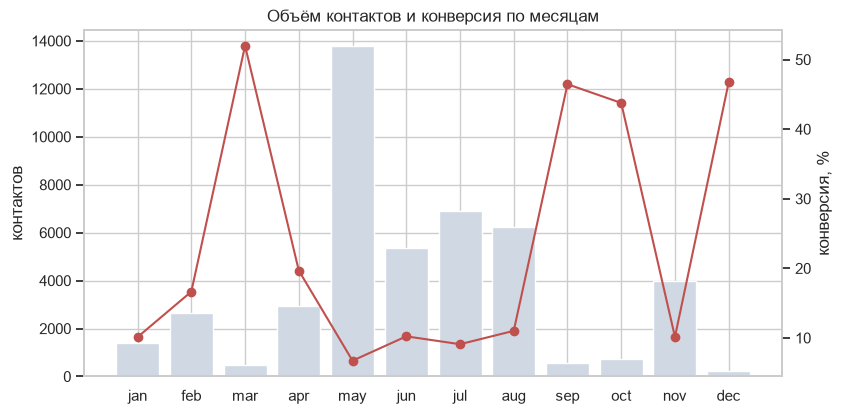

Корреляция Спирмена (объём, конверсия) по месяцам: -0.85


In [16]:
mm = df.groupby('month_num').target.agg(['mean','size']); mm.index = months
fig, ax = plt.subplots(); ax.bar(mm.index, mm['size'], color='#cfd8e3'); ax.set_ylabel('контактов')
ax2 = ax.twinx(); ax2.plot(mm.index, mm['mean']*100, 'o-', color='#c0504d'); ax2.set_ylabel('конверсия, %'); ax2.grid(False)
ax.set_title('Объём контактов и конверсия по месяцам'); plt.show()
print(f"Корреляция Спирмена (объём, конверсия) по месяцам: {stats.spearmanr(mm['size'], mm['mean'])[0]:.2f}")

**Вывод H4 (промежуточный):** связь с месяцем сильная. Март, сентябрь, октябрь, декабрь — конверсия **44–52%**, но это крошечные объёмы (214–738 контактов); май — 30% всех контактов и всего 6.7% конверсии (корреляция Спирмена «объём ↔ конверсия» по месяцам ≈ −0.85). Проверим, не маскируется ли под месяц *год* (см. п. 2.2):

In [17]:
pv = df.pivot_table(index='month_num', columns='year', values='target', aggfunc='mean')*100
cnt = df.pivot_table(index='month_num', columns='year', values='target', aggfunc='size')
pv.index = cnt.index = months
display(pv.round(1).fillna('—').add_prefix('конв.% ').join(cnt.fillna(0).astype(int).add_prefix('n ')))

year,конв.% 2008,конв.% 2009,конв.% 2010,n 2008,n 2009,n 2010
jan,—,3.2,45.8,0,1176,227
feb,—,11.1,52.7,0,2296,353
mar,—,48.4,56.2,0,258,219
apr,—,16.6,58.9,0,2718,214
may,3.2,9.6,57.3,7957,5575,234
jun,4.5,37.5,48.8,4486,642,213
jul,6.0,36.7,54.2,6380,207,308
aug,5.5,34.2,52.3,5215,772,260
sep,—,43.6,49.2,0,282,297
oct,61.3,42.0,40.9,80,438,220


**Вывод H4: гипотеза о «чистой сезонности» не подтверждена — месяц сильно смешан с годом.** Месяцы-лидеры (`mar`, `sep`, `oct`, `dec`) встречаются почти только в 2009–2010, когда банк звонил малому, отобранному кругу и конверсия в целом была 17–52%; а `may`/`jun`/`jul`/`aug` — это в основном массовый 2008-й с ≈5%. Месяц — сильный предиктор *в этих данных*, но во многом как «прокси года/отбора клиентов». ⚠ Для честной оценки: временной split; не интерпретировать `month` как «осенью люди охотнее открывают депозиты».

### H5. Прошлый успех — главный предиктор текущего

In [18]:
t = df.groupby(df.poutcome.astype('object').fillna('no_prev')).target.agg(['mean','size'])
t['lift_vs_avg'] = t['mean']/df.target.mean(); display(t.round(3))
ct = pd.crosstab(df.poutcome.astype('object').fillna('no_prev'), df.target)
print('χ²-p =', stats.chi2_contingency(ct)[1])

,mean,size,lift_vs_avg
poutcome,,,
failure,0.126,4901,1.078
no_prev,0.092,36959,0.783
other,0.167,1840,1.426
success,0.647,1511,5.533


χ²-p = 0.0


**Вывод H5: подтверждена.** Клиенты с `success` в прошлой кампании соглашаются в **64.7%** случаев (lift ≈ 5.5×), при этом их всего 1511 (3.3%). Работает как мощный, но «узкий» признак: хорошо для ранжирования верхушки, мало влияет на общий AUC.

### H6. Долговая нагрузка (`housing`, `loan`) снижает конверсию — и это не просто эффект возраста
Проверим, сохраняется ли эффект ипотеки внутри возрастных групп (иначе это «подмена» возрастом).

In [19]:
age_bin = pd.cut(df.age, [17,30,40,50,60,100], labels=['<=30','31-40','41-50','51-60','60+'])
pt = df.pivot_table(index=age_bin, columns='housing', values='target', aggfunc='mean', observed=True)*100
pt['разница'] = pt['no'] - pt['yes']; display(pt.round(1))
ct = pd.crosstab(df.housing, df.target); print('χ²-p (housing):', stats.chi2_contingency(ct)[1])

housing,no,yes,разница
age,,,
<=30,25.7,9.4,16.3
31-40,14.7,7.7,7.0
41-50,12.0,6.8,5.2
51-60,12.7,6.4,6.2
60+,41.8,48.8,-7.0


χ²-p (housing): 2.918797605076633e-192


**Вывод H6: подтверждена для клиентов до 60 лет, в 60+ эффект обратный.** В группах ≤30 / 31–40 / 41–50 / 51–60 клиенты без ипотеки соглашаются чаще на 16 / 7 / 5 / 6 п.п. — эффект самостоятельный, а не следствие возраста. В группе 60+ картина перевёрнута (41.8% без ипотеки vs 48.8% с ипотекой, но выборка там мала и состоит в основном из пенсионеров — не делаем вывода). Значит, взаимодействие `age × housing` стоит учесть (деревья ловят это сами). `housing`, `loan` и `n_loans` — полезные фичи.

### H7. Баланс и возраст/работа коррелируют между собой (мультиколлинеарность и подмена эффектов)

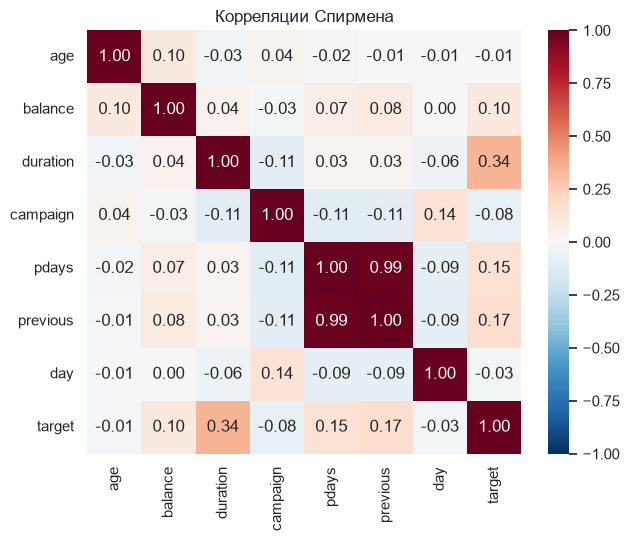

In [20]:
numcols = ['age','balance','duration','campaign','pdays','previous','day','target']
corr = df[numcols].corr(method='spearman')
plt.figure(figsize=(7,5.5)); sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1); plt.title('Корреляции Спирмена'); plt.show()

**Вывод H7:** числовые признаки почти не коррелируют друг с другом (мультиколлинеарность не проблема), кроме естественной пары `pdays`–`previous` (оба описывают прошлые контакты, и оба «сломаны» значением `pdays=-1`). С таргетом линейная связь слабая, у `duration` — самая сильная. Линейные корреляции **недооценивают** U-образный `age` — поэтому для оценки силы признаков лучше смотреть на mutual information:

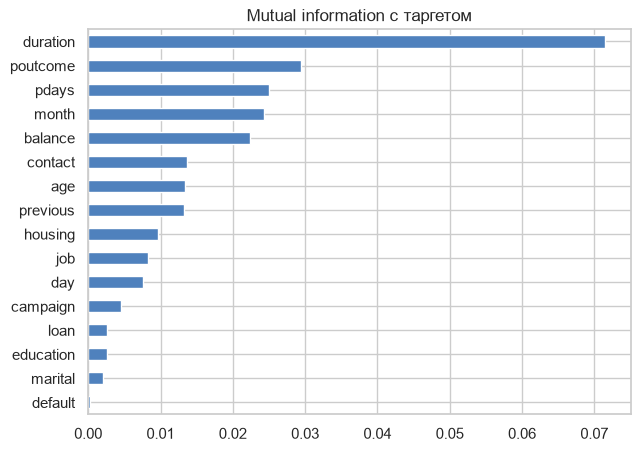

In [21]:
X = df.drop(columns=['y','target','date','day_of_week','year','month_num'])
Xe = X.copy()
for c in Xe.select_dtypes('category').columns: Xe[c] = Xe[c].cat.add_categories('NaN').fillna('NaN').cat.codes
cat_mask = [c in X.select_dtypes('category').columns for c in Xe.columns]
mi = pd.Series(mutual_info_classif(Xe, df.target, discrete_features=cat_mask, random_state=SEED), index=Xe.columns).sort_values()
mi.plot.barh(color='#4f81bd', figsize=(7,5)); plt.title('Mutual information с таргетом'); plt.show()

**Вывод:** порядок по MI: `duration` (0.071) ≫ `poutcome` (0.029) ≈ `pdays` (0.028) ≈ `month` (0.024) > `balance` (0.022) > `contact`, `age` (≈0.013) > `previous`, `housing`, `job`. Слабые по отдельности: `day`, `campaign`, `loan`, `education`, `marital`, `default` (≈0.0003–0.007). Оговорка: MI у `pdays`/`poutcome`/`previous` дублируют друг друга (все про прошлую кампанию), а `month` частично кодирует год (H4).

## 6. Количественная оценка утечки `duration` + быстрый baseline
**Зачем:** превратить «duration подозрительный» в число. Сравним ROC-AUC на 5-fold CV: (а) со всеми признаками, (б) без `duration`. Модель — градиентный бустинг (нативно ест категории и NaN), без тюнинга: цель — не лучший скор, а *оценка вклада*.

Затем — **случайный split vs. временной split** (подтверждение гипотезы о дрейфе из п. 2.2).

In [22]:
feats_all = [c for c in X.columns]
feats_noleak = [c for c in feats_all if c != 'duration']
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
def cv_auc(cols):
    m = HistGradientBoostingClassifier(categorical_features='from_dtype', random_state=SEED, max_iter=200, learning_rate=0.08)
    return cross_val_score(m, df[cols], df.target, cv=cv, scoring='roc_auc').mean()
a_all, a_nl = cv_auc(feats_all), cv_auc(feats_noleak)
print(f'AUC со всеми признаками : {a_all:.3f}')
print(f'AUC без duration        : {a_nl:.3f}   (потеря {a_all-a_nl:.3f})')

AUC со всеми признаками : 0.936
AUC без duration        : 0.801   (потеря 0.135)


In [23]:
# Временной split: train = первые 70% строк (хронологически), test = последние 30%
cut = int(len(df)*.7)
def holdout(cols, name):
    m = HistGradientBoostingClassifier(categorical_features='from_dtype', random_state=SEED, max_iter=200, learning_rate=0.08)
    m.fit(df.loc[:cut-1, cols], df.target[:cut]); return roc_auc_score(df.target[cut:], m.predict_proba(df.loc[cut:, cols])[:,1])
print('Временной split (70/30 по порядку строк):')
print(f'  со всеми признаками: {holdout(feats_all,"all"):.3f}')
print(f'  без duration       : {holdout(feats_noleak,"noleak"):.3f}')
print('Конверсия train/test:', round(df.target[:cut].mean(),3), '/', round(df.target[cut:].mean(),3))

Временной split (70/30 по порядку строк):


  со всеми признаками: 0.729


  без duration       : 0.619
Конверсия train/test: 0.058 / 0.254


**Выводы:**
- **Утечка `duration`:** 5-fold CV AUC **0.936 → 0.801** без него (−0.135). Модель с `duration` «слишком хороша» и неприменима для решения «кого обзванивать»; реалистичная оценка — около 0.80. **В основной модели `duration` не используем** (можно держать как отдельный «upper bound» эксперимент).
- **Дрейф во времени:** при временном split (70/30) AUC падает до **0.729 (с duration) / 0.619 (без)**. Конверсия в train 5.8%, в test 25.4% — распределение таргета радикально меняется. Случайная CV (0.801) **завышает** качество на ≈0.18 относительно честной временной оценки (0.619). Это главный методологический вывод EDA: выбор схемы валидации важнее выбора модели.
- Оговорка: хронологический «хвост» test — это 2009–2010 с совсем другой политикой обзвона; в реальной задаче стоит обсудить с командой, какой сценарий мы моделируем (например, rolling-split по кварталам).

## 7. Идеи для фичей
| Фича | Как считать | Зачем / обоснование |
|---|---|---|
| `prev_contacted` | `pdays != -1` (или `previous > 0`) | Явный флаг вместо «сломанного» `pdays=-1` (H1) |
| `pdays_clean` | `pdays` с `-1 → NaN` (+ бины: <90, 90–200, 200+ дней) | Для моделей на числах; «давность» контакта |
| `poutcome_filled` | `NaN → 'no_prev'` | Осмысленная категория (H1) |
| `contact_unknown` | `contact.isna()` | Артефакт сбора за май/июнь + сильный сигнал (H2) |
| `year`, `quarter`, `date`, `t_index` | Реконструкция из порядка строк (п. 2.2) | Дрейф (5% → 17% → 52%); в модель на «будущее» год подавать нельзя — только для разбиения по времени |
| `month_conv` (таргет-энкодинг) | Среднее таргета по месяцу, **только на train/внутри фолда** | Сильный сезонный сигнал (H4); риск утечки без CV-энкодинга |
| `age_bin` / `age_u = (age-45)^2` | Бины или квадрат | U-образность (п. 4.1) |
| `is_student_or_retired` | `job in {student, retired}` | Лидеры конверсии, компактная фича |
| `balance_log`, `balance_neg` | `sign(b)*log1p(\|b\|)`, `balance<=0` | Скошенность и плато (п. 2.3, 4.1) |
| `n_loans` | `(housing=='yes') + (loan=='yes') + (default=='yes')` | Долговая нагрузка (H6) |
| `campaign_clip`, `campaign_gt3` | `min(campaign, 10)`, `campaign>3` | Убывающая отдача, хвосты |
| `prev_success` | `poutcome=='success'` | Самый сильный бинарный сигнал (H5) |
| `edu_job` | Комбинация `job × education` | Возможное взаимодействие, смотреть на редкость групп |
| `duration_per_contact` | `duration / campaign` | ⚠ **Только** для эксперимента с утечкой |

## 8. Итоговые выводы для построения предиктора

1. **Таргет** несбалансирован (≈11.7% `yes`) → метрики ROC-AUC / PR-AUC / lift@k, стратификация, `class_weight` или подбор порога.
2. **`duration` — утечка**: исключаем из боевой модели; можно оставить как «верхнюю границу» эксперимент.
3. **Пропуски осмысленные**: `poutcome=NaN` ⇔ нет прошлой кампании (≈82%); `contact=NaN` связан с маем–июнем. Заполняем категориями + флаги, а не модой.
4. **`pdays=-1` — маркер**, а не число; `pdays` и `previous` связаны полностью.
5. **`day_of_week` — на самом деле день месяца**; данные упорядочены по времени (2008–2010) → дата восстановима. Конверсия по годам **5% → 17% → 52%**, поэтому **валидировать нужно по времени**: случайная CV даёт AUC 0.80, временной split — 0.62.
6. **Нелинейности**: `age` (U-образно), `balance` (плато), `campaign` (убывает) → бины/деревья/бустинг; для линейных моделей — трансформации.
7. **Самые полезные сигналы** (без `duration`): `poutcome`/`pdays`, `month` (но это во многом прокси года), `balance`, `contact`, `age`, `housing`/`loan`, `job`.
8. **Ограничения:** 2008–2010 (кризис), смещение отбора клиентов по месяцам, редкие категории (`default=yes`, `success`) → осторожно с переобучением на них.

**Следующие шаги:** собрать пайплайн препроцессинга (импутация-флаги + кодирование), временную валидацию, baseline (LogReg) и бустинг; сравнить с/без `duration`; подобрать порог под бизнес-метрику.